# 从零学习 Vision Transformer（ViT）｜PyTorch 中文教程

本 Notebook 从图像切块开始，逐步实现一个小型 ViT，并尝试在 MNIST 手写数字数据集上训练。

**学习路线**
1. 图像为什么可以变成 token 序列
2. Patch Embedding 与位置编码
3. 多头自注意力（Multi-Head Self-Attention）
4. Transformer Encoder Block、残差连接与 MLP
5. `[CLS]` token 和分类头
6. 训练、评估、查看预测错误
7. 动手实验与自测问题

环境：PyTorch、torchvision、matplotlib。设备会按 CUDA → Apple Silicon MPS → CPU 的顺序自动选择。首次运行 MNIST 数据集单元格需要联网下载数据。这个模型是教学用 TinyViT，不是论文中的大规模 ViT。

## 1. ViT 的整体思路

CNN 常用卷积提取局部特征；Vision Transformer（ViT）把图像切成许多小块（patch），将每个 patch 映射为一个向量，再用 Transformer 学习这些向量之间的关系。

本教程使用 `28×28` 的灰度图像和 `7×7` 的 patch：
- 每张图有 `(28/7) × (28/7) = 16` 个 patches。
- 每个 patch 有 `7×7×1 = 49` 个像素值。
- 每个 patch 被投影到 `D=64` 维 embedding。
- 添加一个可学习的 `[CLS]` token 后，序列长度为 `17`。
- Encoder 处理整个序列，最后用 CLS 对应的向量预测图像类别。

流程：图像 → patches → embedding + 位置编码 → Transformer Encoder → CLS 向量 → 分类 logits。

## 2. 导入库与选择设备

`.to(device)` 会把模型或张量放到指定设备。Mac 上如果 MPS 可用，可以尝试 Apple Silicon GPU；否则使用 CPU。

In [1]:
import math
import random
import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

torch.manual_seed(0)
random.seed(0)

PyTorch: 2.2.2
Device: mps


## 3. Patch Embedding：把图像切成 token

输入图像形状是 `(B, C, H, W)`。如果 patch 边长为 `P`，patch 数量为：

\[
N = (H/P)(W/P)
\]

每个 patch 展平后有 `P²C` 个值，再映射到 `D` 维向量。我们用 `Conv2d(kernel_size=P, stride=P)` 实现切块与线性投影：每个卷积窗口恰好覆盖一个 patch。

In [2]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size=28, patch_size=7, in_channels=1, embed_dim=64):
        super().__init__()
        assert image_size % patch_size == 0
        self.num_patches = (image_size // patch_size) ** 2
        self.proj = nn.Conv2d(
            in_channels, embed_dim,
            kernel_size=patch_size, stride=patch_size
        )

    def forward(self, x):
        # (B,C,H,W) -> (B,D,H/P,W/P) -> (B,D,N) -> (B,N,D)
        x = self.proj(x)
        x = x.flatten(2)
        return x.transpose(1, 2)

patch_embed = PatchEmbedding()
dummy = torch.randn(2, 1, 28, 28)
tokens = patch_embed(dummy)
print("输入:", dummy.shape)
print("Patch tokens:", tokens.shape)  # (2, 16, 64)

输入: torch.Size([2, 1, 28, 28])
Patch tokens: torch.Size([2, 16, 64])


## 4. 位置编码与 CLS token

Self-Attention 本身不直接知道每个 patch 在图像的哪个位置，所以 ViT 会加上位置嵌入。这里使用可学习的位置参数。

另外添加可学习的 `[CLS]` token，作为整张图像的汇总表示：

\[
Z_0 = [x_{cls};x_1;\ldots;x_N] + E_{pos}
\]

`[CLS]` 是额外的 token，不是图像像素。最后分类时取 Encoder 输出中的第 0 个位置。

## 5. Multi-Head Self-Attention

从输入 `X` 通过线性层得到 Query、Key、Value：

\[
Q=XW_Q,\quad K=XW_K,\quad V=XW_V
\]

Scaled dot-product attention：

\[
\operatorname{Attention}(Q,K,V)
=\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
\]

直觉上，Q 和 K 决定 token 之间应该互相关注多少，V 是最终被加权汇总的信息。多头注意力把隐藏维度拆成多个 head。图像分类 ViT 通常不使用 causal mask，每个 patch 都可以关注所有其他 patches。

In [3]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embed_dim=64, num_heads=4, dropout=0.0):
        super().__init__()
        assert embed_dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        self.qkv = nn.Linear(embed_dim, 3 * embed_dim)
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.attn_drop = nn.Dropout(dropout)
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x):
        B, N, D = x.shape
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim)
        qkv = qkv.permute(2, 0, 3, 1, 4)  # (3,B,heads,N,head_dim)
        q, k, v = qkv[0], qkv[1], qkv[2]
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        attn = self.attn_drop(scores.softmax(dim=-1))
        out = attn @ v                       # (B,heads,N,head_dim)
        out = out.transpose(1, 2).contiguous().reshape(B, N, D)
        return self.proj_drop(self.proj(out))

attn = MultiHeadSelfAttention(64, 4)
x = torch.randn(2, 17, 64)
print("Attention 输入/输出:", x.shape, attn(x).shape)

Attention 输入/输出: torch.Size([2, 17, 64]) torch.Size([2, 17, 64])


## 6. Transformer Encoder Block

本教程使用 Pre-LayerNorm 结构：

\[
X' = X + \operatorname{MSA}(\operatorname{LN}(X))
\]
\[
X_{out} = X' + \operatorname{MLP}(\operatorname{LN}(X'))
\]

- **Attention**：在不同 token 之间交换信息。
- **MLP**：对每个 token 的向量独立做非线性变换。
- **Residual connection**：把输入加回子层输出，帮助信息和梯度传播。
- **LayerNorm**：对每个 token 的特征维度做归一化。

In [4]:
class MLP(nn.Module):
    def __init__(self, embed_dim=64, mlp_ratio=4, dropout=0.0):
        super().__init__()
        hidden = embed_dim * mlp_ratio
        self.net = nn.Sequential(
            nn.Linear(embed_dim, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerEncoderBlock(nn.Module):
    def __init__(self, embed_dim=64, num_heads=4, mlp_ratio=4, dropout=0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = MLP(embed_dim, mlp_ratio, dropout)

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

block = TransformerEncoderBlock()
print("Block 输出:", block(torch.randn(2, 17, 64)).shape)

Block 输出: torch.Size([2, 17, 64])


## 7. 组装 TinyViT

模型把 patch tokens 与 CLS token 拼接，加入位置嵌入，然后通过若干 Encoder Blocks。最后取 `x[:, 0]` 作为图像表示，分类头输出 10 个类别的 logits。

注意：`CrossEntropyLoss` 需要原始 logits，不要在传入 loss 前手动 softmax。

In [5]:
class TinyViT(nn.Module):
    def __init__(
        self, image_size=28, patch_size=7, in_channels=1,
        num_classes=10, embed_dim=64, depth=3, num_heads=4,
        mlp_ratio=4, dropout=0.0
    ):
        super().__init__()
        self.patch_embed = PatchEmbedding(
            image_size, patch_size, in_channels, embed_dim
        )
        n_patches = self.patch_embed.num_patches
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([
            TransformerEncoderBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward(self, x):
        B = x.shape[0]
        x = self.patch_embed(x)                # (B,N,D)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)         # (B,N+1,D)
        x = self.pos_drop(x + self.pos_embed)
        for block in self.blocks:
            x = block(x)
        x = self.norm(x)
        return self.head(x[:, 0])              # (B,num_classes)

model = TinyViT().to(device)
print("模型输出:", model(torch.randn(4, 1, 28, 28, device=device)).shape)
print("可训练参数量:", sum(p.numel() for p in model.parameters() if p.requires_grad))

模型输出: torch.Size([4, 10])
可训练参数量: 155082


## 8. 下载 MNIST 数据

MNIST 有 10 个类别（数字 0–9）。为了让初次训练更快，默认只使用一部分数据。首次运行需要下载数据；如果下载失败，前面的模型与形状测试仍然可以运行。

In [6]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

transform = transforms.ToTensor()
train_full = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_full = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_dataset = Subset(train_full, range(10000))
test_dataset = Subset(test_full, range(2000))
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("图像 batch:", images.shape)
print("标签 batch:", labels.shape)

Failed to download (trying next):
HTTP Error 404: Not Found



1.0%

100.0%


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%

...

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

图像 batch: torch.Size([128, 1, 28, 28])
标签 batch: torch.Size([128])


## 9. 可视化图像

观察模型实际接收的输入：单通道、大小为 `28×28` 的灰度图。

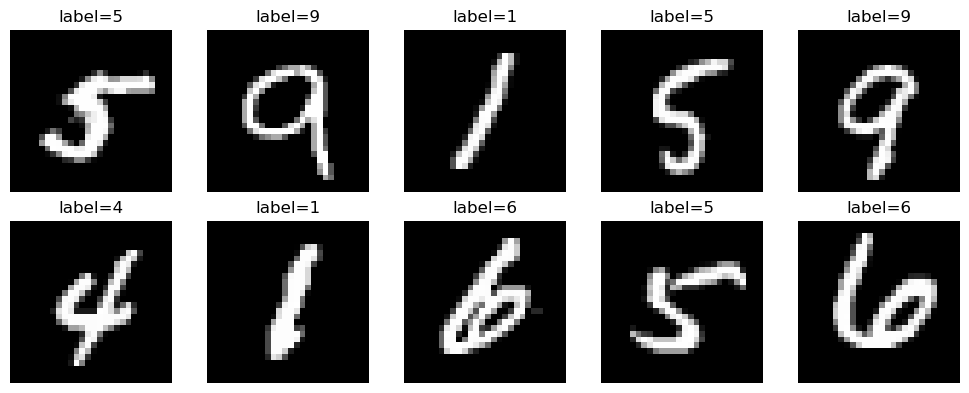

In [7]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i, 0], cmap="gray")
    ax.set_title(f"label={labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 10. 训练与评估

每一步训练的顺序：
1. 前向传播：`logits = model(images)`
2. 计算 loss：`criterion(logits, labels)`
3. 清空旧梯度：`optimizer.zero_grad()`
4. 自动微分：`loss.backward()`
5. 更新参数：`optimizer.step()`

这里的标签是类别 ID，而不是语言模型里的下一个 token。

In [13]:
model = TinyViT(
    image_size=28, patch_size=7, in_channels=1, num_classes=10,
    embed_dim=64, depth=3, num_heads=4, dropout=0.1
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)

def evaluate(model, loader):
    model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            total_correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, total_correct / total

def train_one_epoch(model, loader):
    model.train()
    total_loss, total = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion(logits, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        total += labels.size(0)
    return total_loss / total

history = {"train_loss": [], "test_loss": [], "test_acc": []}
num_epochs = 20  # 想提升效果可以改成 5 或 10；CPU 运行可能较慢

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, train_loader)
    test_loss, test_acc = evaluate(model, test_loader)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"train_loss={train_loss:.4f} | test_loss={test_loss:.4f} | "
        f"test_acc={test_acc:.2%}"
    )

Epoch 1/20 | train_loss=1.8880 | test_loss=1.5324 | test_acc=46.40%
Epoch 2/20 | train_loss=1.3136 | test_loss=1.1216 | test_acc=60.25%
Epoch 3/20 | train_loss=1.0903 | test_loss=0.9502 | test_acc=66.55%
Epoch 4/20 | train_loss=0.9263 | test_loss=0.8492 | test_acc=73.65%
Epoch 5/20 | train_loss=0.7957 | test_loss=0.7119 | test_acc=77.65%
Epoch 6/20 | train_loss=0.7232 | test_loss=0.6520 | test_acc=78.95%
Epoch 7/20 | train_loss=0.6558 | test_loss=0.5634 | test_acc=82.45%
Epoch 8/20 | train_loss=0.6062 | test_loss=0.5342 | test_acc=83.20%
Epoch 9/20 | train_loss=0.5579 | test_loss=0.4993 | test_acc=84.10%
Epoch 10/20 | train_loss=0.5200 | test_loss=0.4703 | test_acc=85.60%
Epoch 11/20 | train_loss=0.5034 | test_loss=0.4264 | test_acc=86.90%
Epoch 12/20 | train_loss=0.4572 | test_loss=0.4374 | test_acc=87.05%
Epoch 13/20 | train_loss=0.4502 | test_loss=0.3921 | test_acc=87.75%
Epoch 14/20 | train_loss=0.4140 | test_loss=0.3814 | test_acc=88.75%
Epoch 15/20 | train_loss=0.3949 | test_loss

## 11. 观察训练曲线

训练 loss 通常会逐步下降。准确率会受随机初始化、数据子集和训练轮数影响，每次运行不一定完全一样。

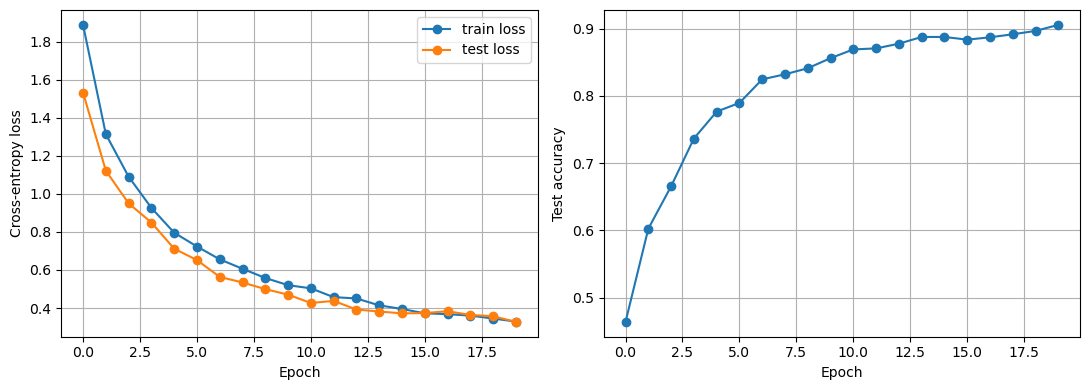

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], marker="o", label="train loss")
axes[0].plot(history["test_loss"], marker="o", label="test loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(history["test_acc"], marker="o")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test accuracy")
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 12. 查看预测错误的图片

`argmax(dim=1)` 选择 logits 分数最高的类别。看看模型在哪些图像上出错，有助于理解准确率之外的模型行为。

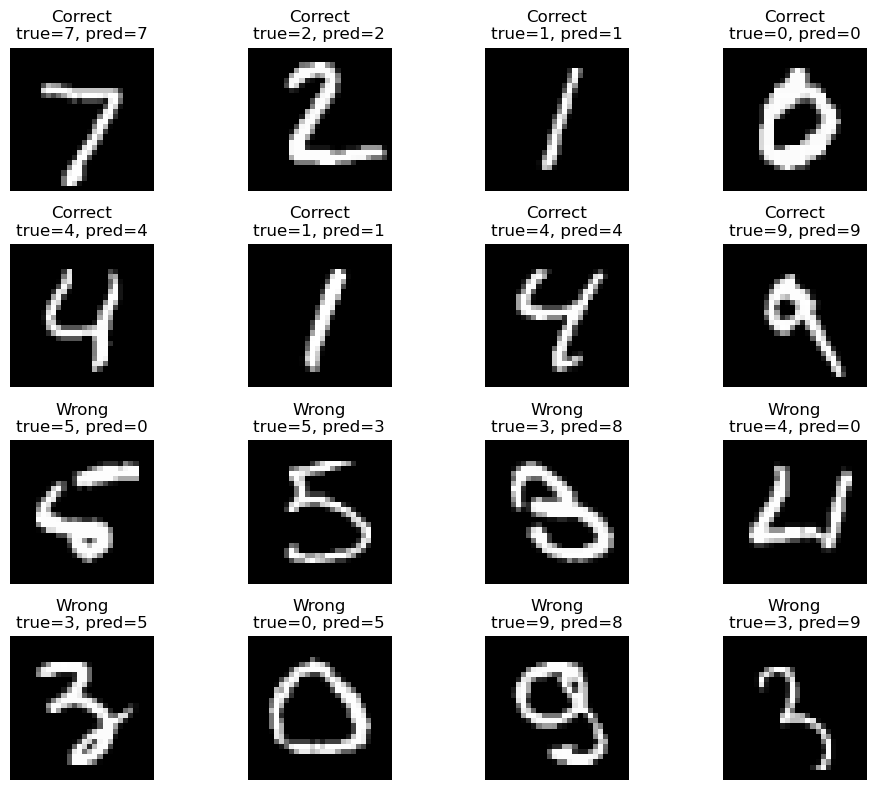

In [17]:
model.eval()
images, labels = next(iter(test_loader))

with torch.no_grad():
    predictions = model(images.to(device)).argmax(dim=1).cpu()

correct = (predictions == labels).nonzero(as_tuple=True)[0]
wrong = (predictions != labels).nonzero(as_tuple=True)[0]

fig, axes = plt.subplots(4, 4, figsize=(10, 8))

# 前两行：8 张预测正确的图片
for j, ax in enumerate(axes[:2].flat):
    if j < len(correct):
        idx = correct[j].item()
        ax.imshow(images[idx, 0], cmap="gray")
        ax.set_title(
            f"Correct\ntrue={labels[idx].item()}, "
            f"pred={predictions[idx].item()}"
        )
    ax.axis("off")

# 后两行：8 张预测错误的图片
for j, ax in enumerate(axes[2:].flat):
    if j < len(wrong):
        idx = wrong[j].item()
        ax.imshow(images[idx, 0], cmap="gray")
        ax.set_title(
            f"Wrong\ntrue={labels[idx].item()}, "
            f"pred={predictions[idx].item()}"
        )
    ax.axis("off")

plt.tight_layout()
plt.show()

## 13. 实验与自测

可以一次只改变一个变量，观察输出形状、训练速度和准确率。

1. 把 `patch_size=7` 改成 `4`。因为 `28` 能被 `4` 整除，patch 数量从 16 变成 49。
2. 把 `embed_dim=64` 改成 `128`，同时确保 `embed_dim` 能被 `num_heads` 整除。
3. 比较 `num_heads=2, 4, 8`。
4. 比较 `depth=1, 3, 6`。
5. 增加训练样本数量和 `num_epochs`。
6. 尝试不使用 CLS token，而是对所有 patch 输出取平均，再接分类头。
7. 尝试让 Attention 返回注意力矩阵，并可视化 CLS token 对不同 patches 的注意力。

**自测问题**
- 为什么 Patch Embedding 输出 `(B,N,D)`？
- 为什么需要位置编码？
- 为什么图像分类 ViT 通常不使用 causal mask？
- 为什么注意力分数矩阵形状是 `(B, heads, N, N)`？
- `loss.backward()` 和 `optimizer.step()` 分别做什么？
- 为什么交叉熵的输入是 logits，而不是 softmax 后的概率？

## 14. 总结

ViT 把图像分类转化成序列建模：图像切成 patches，patches 变成 embeddings，加上位置编码，通过 Transformer Encoder 建模全局关系，最后由分类头输出类别。这个教学版 TinyViT 适合学习核心机制，但并不等同于论文中用于大规模预训练的完整 ViT。